<center><h1>Chun-Fu_Liu_HW6</h1></center>

Name: Chun-Fu Liu
<br>
Github Username: Albert927
<br>
USC ID: 5635413630

## 1. Tree-Based Methods

Import packages

In [1]:
from pathlib import Path
import pandas as pd

### (a) Download the APS Failure data

In [4]:
DATA_DIR = Path(
    r"C:\Users\liual\Desktop\DSCI 552\HW\hw6\Homework 6 Data"
)

train_df = pd.read_csv(
    DATA_DIR / "aps_failure_training_set.csv",
    skiprows=20,
    na_values="na"
)

test_df = pd.read_csv(
    DATA_DIR / "aps_failure_test_set.csv",
    skiprows=20,
    na_values="na"
)

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)

Training shape: (60000, 171)
Test shape: (16000, 171)


In [5]:
# Separate features (X) and target labels (y)
X_train = train_df.drop(columns="class").copy()
y_train = train_df["class"].copy()

X_test = test_df.drop(columns="class").copy()
y_test = test_df["class"].copy()

### (b) Data Preparation

#### (i) Research what types of techniques are usually used

In [6]:
# Calculate the median of each feature separately
train_medians = X_train.median()
test_medians = X_test.median()

# Fill missing values while preserving the original data
X_train_imputed = X_train.fillna(train_medians)
X_test_imputed = X_test.fillna(test_medians)

# Check the results
print("Missing values after imputation:")
print("Training:", X_train_imputed.isna().sum().sum())
print("Test:", X_test_imputed.isna().sum().sum())

Missing values after imputation:
Training: 0
Test: 0


Common missing-value methods include mean, median, and KNN imputation. Median imputation was selected for its robustness to extreme values and computational efficiency. Following the assignment footnote, training and test values were imputed using their respective feature medians.

#### (ii) Calculate the coefficient of variation

In [7]:
# Calculate feature statistics using the imputed training data
feature_means = X_train_imputed.mean()
feature_stds = X_train_imputed.std(ddof=1)

# CV is undefined when the mean is zero
feature_cv = feature_stds / feature_means.replace(0, float("nan"))

# Organize the results for all 170 features
cv_summary = pd.DataFrame({
    "mean": feature_means,
    "sample_std": feature_stds,
    "CV": feature_cv
})

cv_summary = cv_summary.sort_values("CV", ascending=False)


display(cv_summary)

,mean,sample_std,CV
cf_000,1.431075e+05,3.504525e+07,244.887517
co_000,1.433300e+05,3.504525e+07,244.507385
ad_000,1.434383e+05,3.504525e+07,244.322816
cs_009,7.705097e+02,1.833278e+05,237.930554
dh_000,4.392641e+03,5.412441e+05,123.216097
...,...,...,...
bo_000,3.258947e+05,2.582334e+05,0.792383
bp_000,3.420739e+05,2.577156e+05,0.753392
bq_000,3.573117e+05,2.567407e+05,0.718534
br_000,3.713041e+05,2.558701e+05,0.689112


#### (iii) Plot a correlation matrix

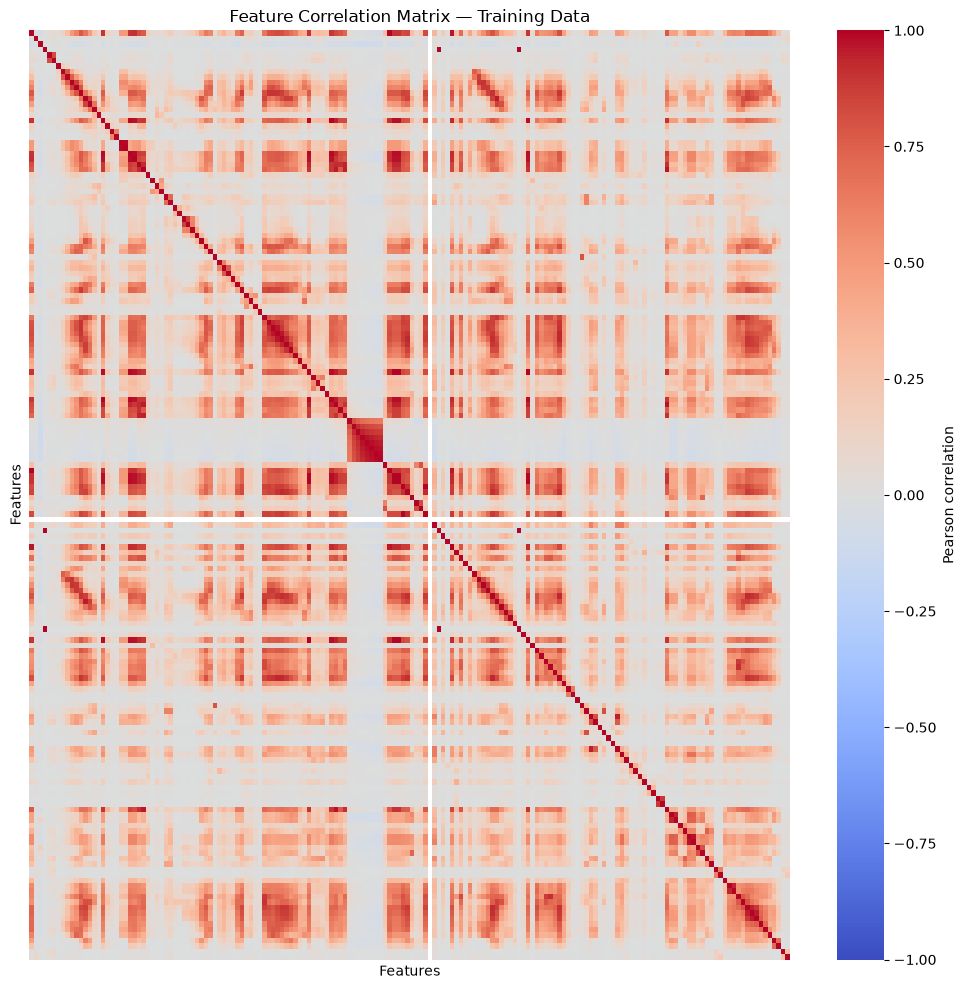

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate Pearson correlations using all 170 features
correlation_matrix = X_train_imputed.corr()

# Visualize the correlation matrix
plt.figure(figsize=(10, 10))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=False,
    yticklabels=False,
    cbar_kws={"label": "Pearson correlation"}
)

plt.title("Feature Correlation Matrix — Training Data")
plt.xlabel("Features")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

#### (iv) Make scatter plots and box plots

Top 13 features by CV:
['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


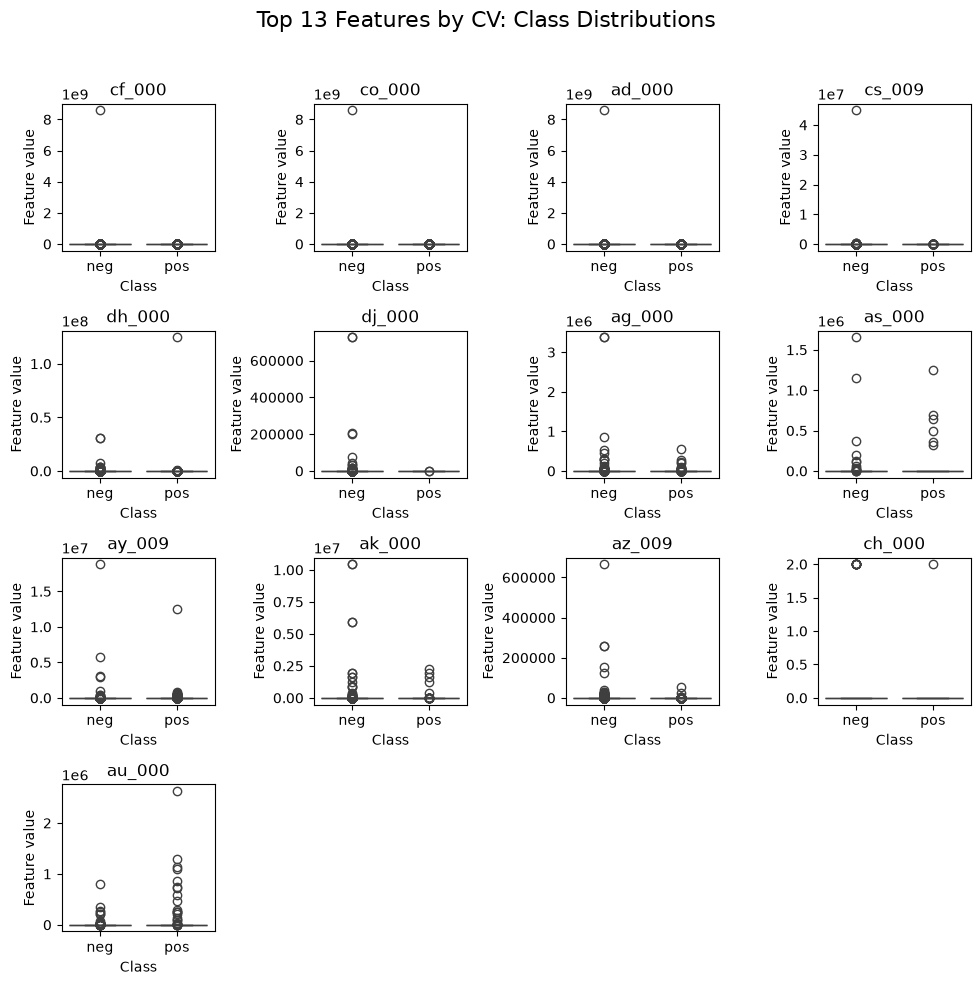

In [12]:
# Select the 13 features with the highest coefficients of variation
top_features = cv_summary["CV"].nlargest(13).index.tolist()

print("Top 13 features by CV:")
print(top_features)

# Add class labels for visualization
plot_df = X_train_imputed[top_features].copy()
plot_df["class"] = y_train

# Compare feature distributions between the two classes
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
axes = axes.flatten()

for ax, feature in zip(axes, top_features):
    sns.boxplot(
        data=plot_df,
        x="class",
        y=feature,
        order=["neg", "pos"],
        ax=ax
    )
    ax.set_title(feature)
    ax.set_xlabel("Class")
    ax.set_ylabel("Feature value")

# Hide unused panels
for ax in axes[len(top_features):]:
    ax.set_visible(False)

fig.suptitle("Top 13 Features by CV: Class Distributions", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

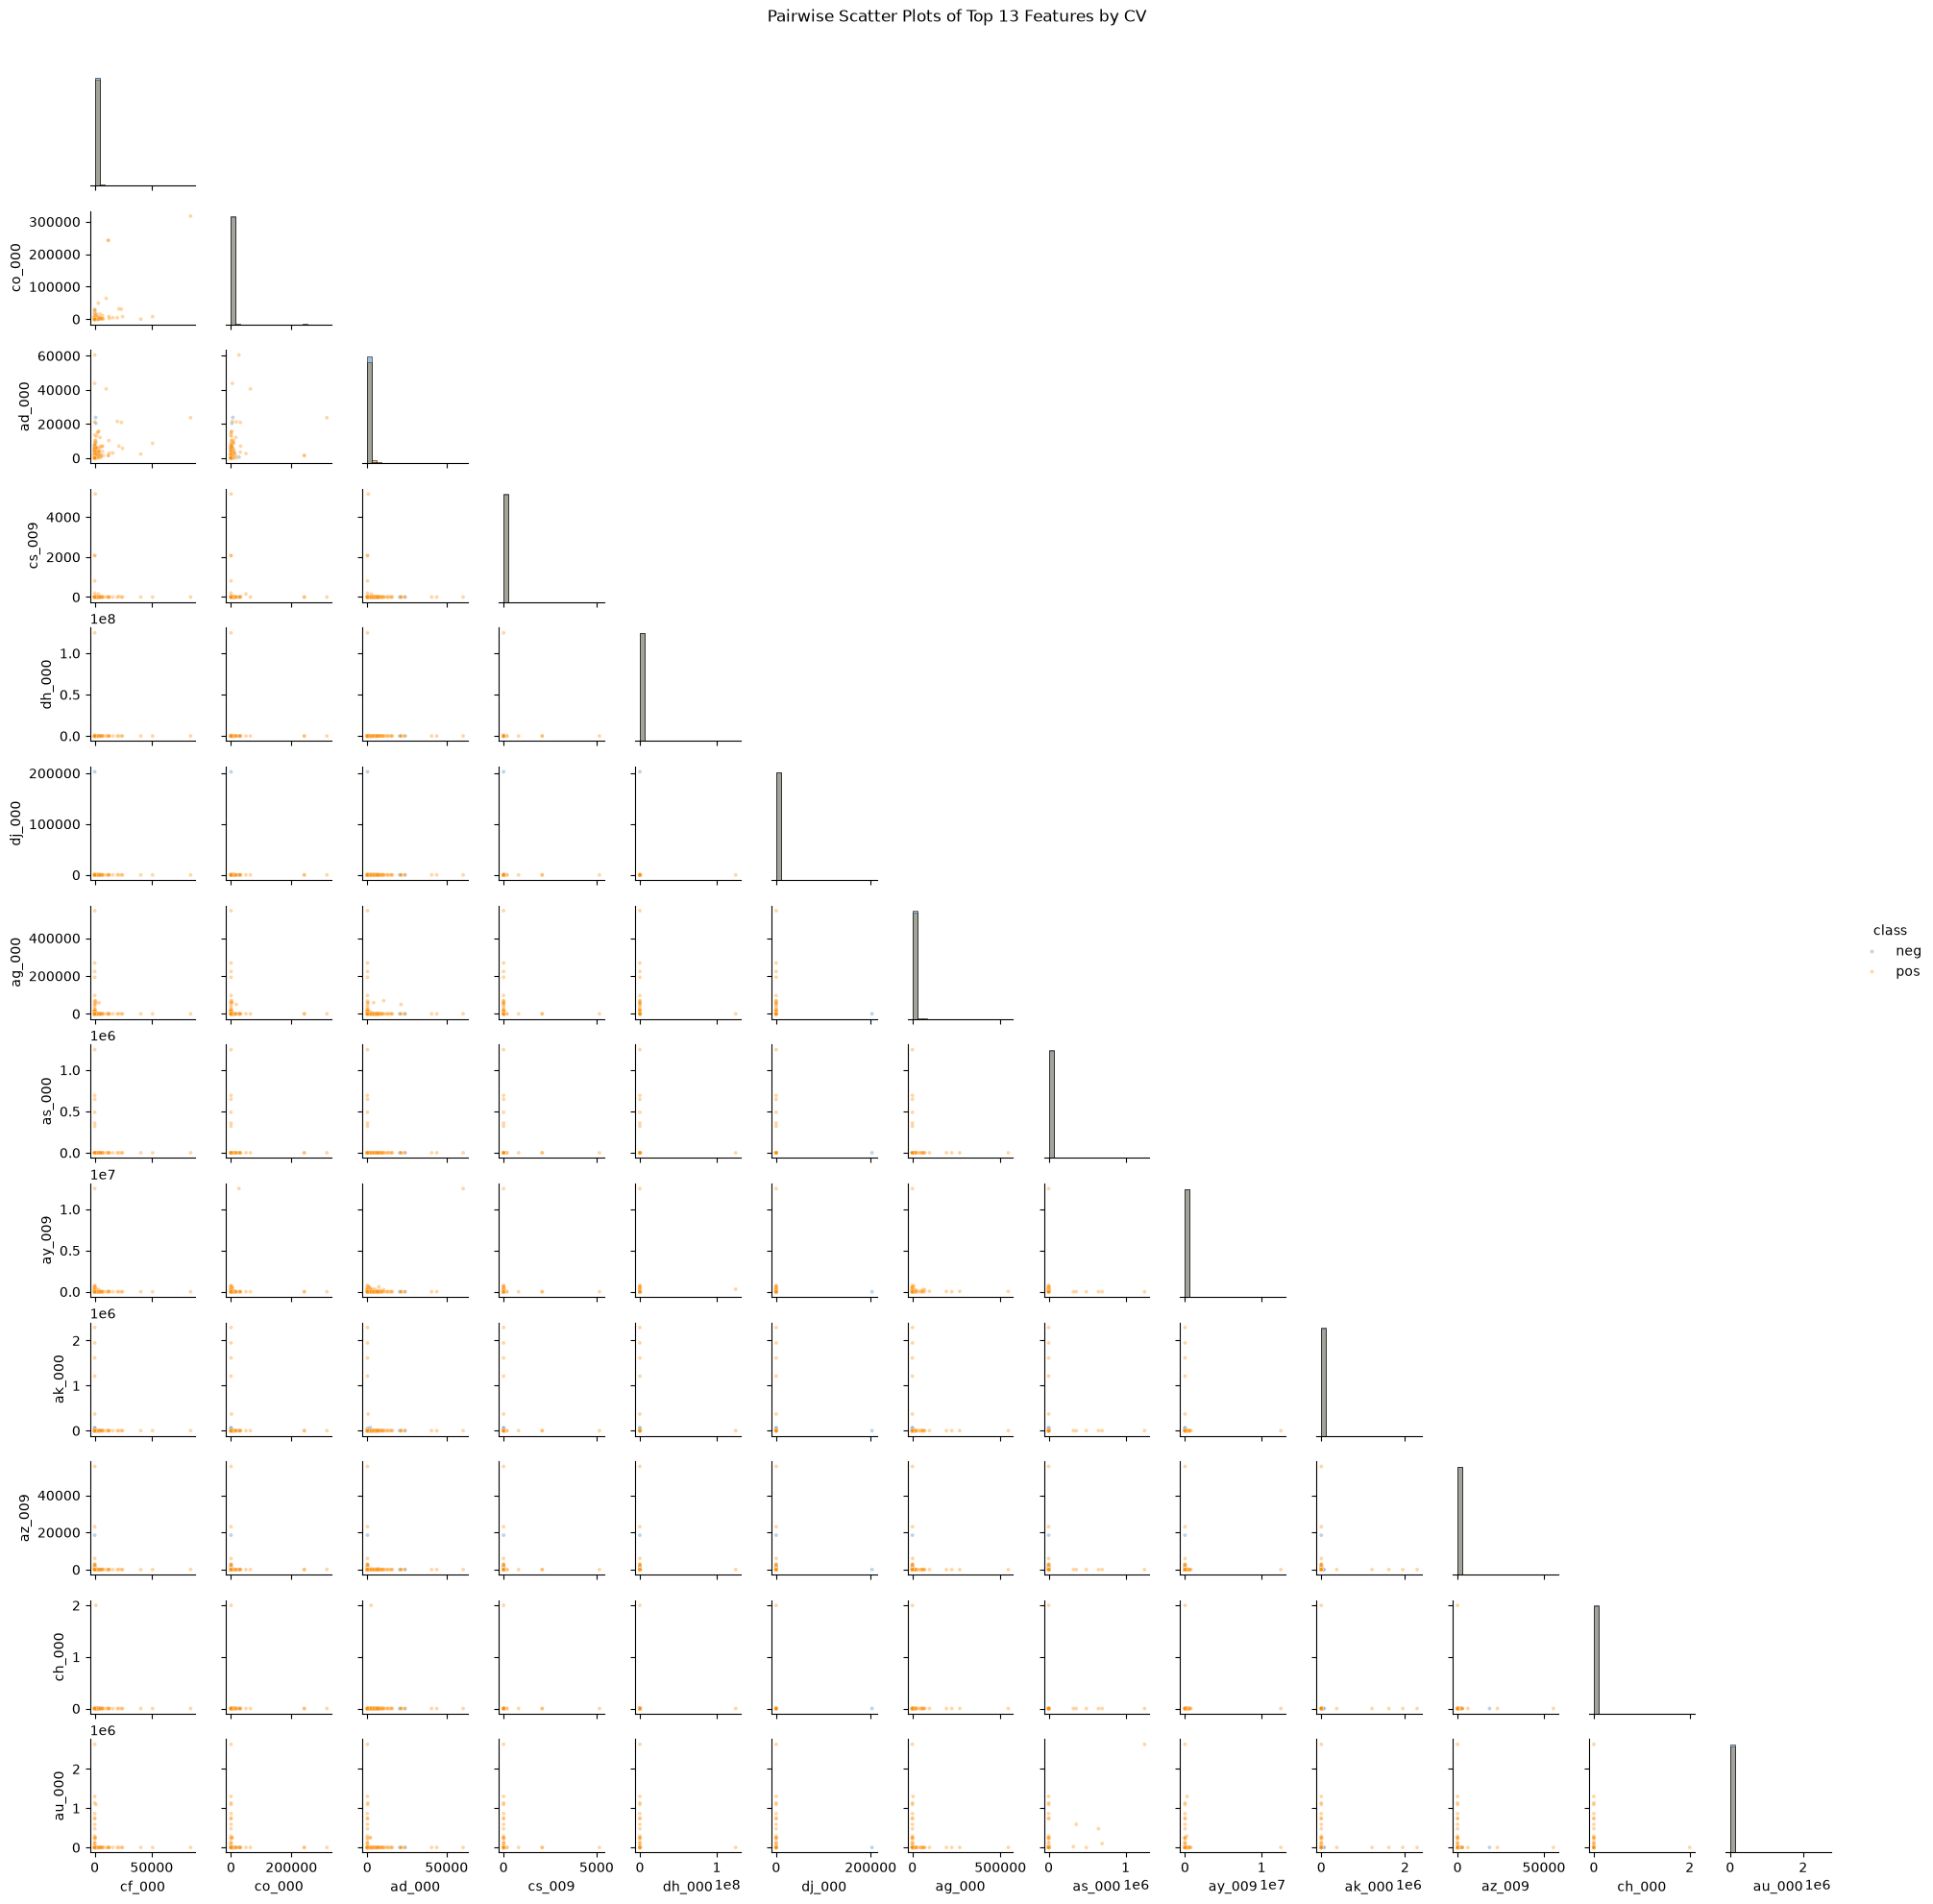

In [15]:
# Sample each class separately for visualization
scatter_df = pd.concat([
    plot_df[plot_df["class"] == label].sample(
        n=min(1000, (plot_df["class"] == label).sum()),
        random_state=42
    )
    for label in ["neg", "pos"]
])

# Plot pairwise relationships among the selected features
g = sns.pairplot(
    data=scatter_df,
    vars=top_features,
    hue="class",
    hue_order=["neg", "pos"],
    palette={"neg": "steelblue", "pos": "darkorange"},
    corner=True,
    diag_kind="hist",
    height=1.5,
    plot_kws={"s": 8, "alpha": 0.35},
    diag_kws={"bins": 20}
)

g.fig.suptitle(
    "Pairwise Scatter Plots of Top 13 Features by CV",
    y=1.02
)
plt.show()

#### (v) Is this data set imbalanced?

In [16]:
# Summarize the class distribution in the training set
class_summary = pd.DataFrame({
    "count": y_train.value_counts(),
    "percentage": y_train.value_counts(normalize=True) * 100
})

display(class_summary)

negative_count = (y_train == "neg").sum()
positive_count = (y_train == "pos").sum()

print(
    f"Negative-to-positive ratio: "
    f"{negative_count / positive_count:.0f}:1"
)

,count,percentage
class,,
neg,59000,98.333333
pos,1000,1.666667


Negative-to-positive ratio: 59:1


### (c) Train a random forest

In [17]:
from sklearn.ensemble import RandomForestClassifier

# Train a baseline random forest without class imbalance compensation
rf_baseline = RandomForestClassifier(
    n_estimators=100,
    class_weight=None,
    bootstrap=True,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

rf_baseline.fit(X_train_imputed, y_train)

In [ ]:
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report)

# Predict labels for the training and test sets
y_train_pred = rf_baseline.predict(X_train_imputed)
y_test_pred = rf_baseline.predict(X_test_imputed)

# Report confusion matrices and classification metrics
for name, y_true, y_pred in [
    ("Training", y_train, y_train_pred),
    ("Test", y_test, y_test_pred)
]:
    cm = confusion_matrix(y_true, y_pred, labels=["neg", "pos"])

    cm_table = pd.DataFrame(
        cm,
        index=["Actual neg", "Actual pos"],
        columns=["Predicted neg", "Predicted pos"]
    )

    print(f"\n{name} confusion matrix:")
    display(cm_table)

    error = 1 - accuracy_score(y_true, y_pred)
    print(f"{name} misclassification rate: {error:.4f}")


# Compare OOB error with test error
oob_error = 1 - rf_baseline.oob_score_
test_error = 1 - accuracy_score(y_test, y_test_pred)

print(f"OOB error: {oob_error:.4f}")
print(f"Test error: {test_error:.4f}")


Training confusion matrix:


,Predicted neg,Predicted pos
Actual neg,59000,0
Actual pos,1,999


Training misclassification rate: 0.0000
Test confusion matrix:


,Predicted neg,Predicted pos
Actual neg,15610,15
Actual pos,106,269


Test misclassification rate: 0.0076
OOB error: 0.0062
Test error: 0.0076


Training AUC: 1.0000
Test AUC: 0.9928


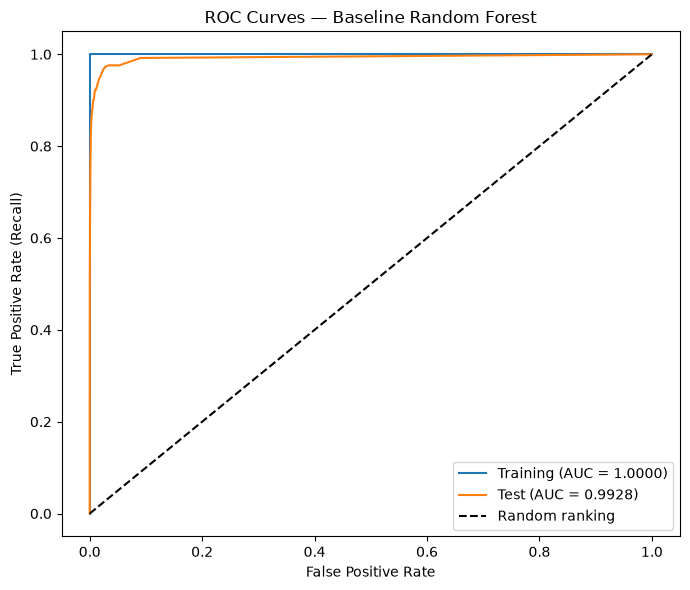

In [19]:
import numpy as np
from sklearn.metrics import roc_curve, roc_auc_score

# Find the probability column corresponding to the positive class
pos_index = list(rf_baseline.classes_).index("pos")

train_scores = rf_baseline.predict_proba(X_train_imputed)[:, pos_index]
test_scores = rf_baseline.predict_proba(X_test_imputed)[:, pos_index]

plt.figure(figsize=(7, 6))

for name, y_true, scores in [
    ("Training", y_train, train_scores),
    ("Test", y_test, test_scores)
]:
    # Encode pos as 1 and neg as 0
    y_binary = (np.asarray(y_true) == "pos").astype(int)

    fpr, tpr, thresholds = roc_curve(y_binary, scores)
    auc = roc_auc_score(y_binary, scores)

    print(f"{name} AUC: {auc:.4f}")
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], "k--", label="Random ranking")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves — Baseline Random Forest")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### (d) Research class imbalance in random forest

In [20]:
# Train a random forest with balanced class weights
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    bootstrap=True,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

rf_balanced.fit(X_train_imputed, y_train)

c:\Users\liual\miniconda3\envs\dsci-552\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(



Training confusion matrix:


,Predicted neg,Predicted pos
Actual neg,58986,14
Actual pos,0,1000


Training misclassification rate: 0.000233
Test confusion matrix:


,Predicted neg,Predicted pos
Actual neg,15571,54
Actual pos,99,276


Test misclassification rate: 0.009563


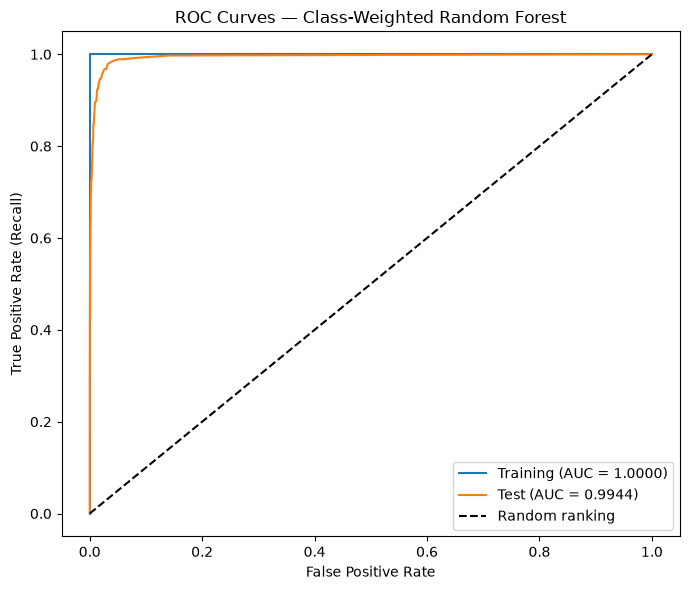

Evaluation summary:


,misclassification_rate,pos_recall,specificity,AUC
Training,0.000233,1.000,0.999763,1.000000
Test,0.009563,0.736,0.996544,0.994403


OOB error: 0.020217
Test error: 0.009563


In [21]:
# Evaluate the class-weighted random forest
balanced_results = {}
balanced_curves = {}

pos_index = list(rf_balanced.classes_).index("pos")

for name, X, y_true in [
    ("Training", X_train_imputed, y_train),
    ("Test", X_test_imputed, y_test)
]:
    y_pred = rf_balanced.predict(X)
    scores = rf_balanced.predict_proba(X)[:, pos_index]

    cm = confusion_matrix(y_true, y_pred, labels=["neg", "pos"])
    tn, fp, fn, tp = cm.ravel()

    y_binary = (np.asarray(y_true) == "pos").astype(int)
    fpr, tpr, _ = roc_curve(y_binary, scores)
    auc = roc_auc_score(y_binary, scores)
    error = 1 - accuracy_score(y_true, y_pred)

    balanced_results[name] = {
        "misclassification_rate": error,
        "pos_recall": tp / (tp + fn),
        "specificity": tn / (tn + fp),
        "AUC": auc
    }
    balanced_curves[name] = (fpr, tpr, auc)

    print(f"\n{name} confusion matrix:")
    display(pd.DataFrame(
        cm,
        index=["Actual neg", "Actual pos"],
        columns=["Predicted neg", "Predicted pos"]
    ))

    print(f"{name} misclassification rate: {error:.6f}")

# Plot ROC curves
plt.figure(figsize=(7, 6))

for name, (fpr, tpr, auc) in balanced_curves.items():
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], "k--", label="Random ranking")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves — Class-Weighted Random Forest")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Evaluation summary:")
display(pd.DataFrame(balanced_results).T)

print(f"OOB error: {1 - rf_balanced.oob_score_:.6f}")
print(
    f"Test error: "
    f"{balanced_results['Test']['misclassification_rate']:.6f}"
)

Balanced class weights increased test positive-class recall from 71.73% to 73.60% and AUC from 0.9928 to 0.9944, but increased false positives from 15 to 54 and test error from 0.7563% to 0.9563%. Thus, improved failure detection came with more false alarms. OOB error (2.0217%) exceeded test error (0.9563%); the training output also contains an OOB reliability warning.

### (e) XGBoost and Model Trees

In [22]:
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold

# Encode the target labels for XGBoost
y_train_binary = y_train.map({"neg": 0, "pos": 1})
y_test_binary = y_test.map({"neg": 0, "pos": 1})

# Define stratified five-fold cross-validation
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [23]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# Fit imputation separately within each cross-validation fold
xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", xgb.XGBClassifier(
        booster="gbtree",
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        scale_pos_weight=1,
        random_state=42,
        n_jobs=4
    ))
])

# Compare four positive L1 regularization strengths
alpha_grid = {
    "model__reg_alpha": [0.01, 0.1, 1.0, 10.0]
}

xgb_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=alpha_grid,
    scoring="accuracy",
    cv=cv_strategy,
    refit=True,
    n_jobs=1,
    verbose=1,
    error_score="raise"
)

# Use the original training features, before imputation
xgb_search.fit(X_train, y_train_binary)

cv_results = pd.DataFrame({
    "alpha": [
        params["model__reg_alpha"]
        for params in xgb_search.cv_results_["params"]
    ],
    "mean_cv_error": 1 - xgb_search.cv_results_["mean_test_score"],
    "std_cv_error": xgb_search.cv_results_["std_test_score"]
}).sort_values("mean_cv_error")

display(cv_results)

print("Best alpha:", xgb_search.best_params_["model__reg_alpha"])
print(f"Best mean CV error: {1 - xgb_search.best_score_:.6f}")

Fitting 5 folds for each of 4 candidates, totalling 20 fits


,alpha,mean_cv_error,std_cv_error
1,0.10,0.006967,0.000598
0,0.01,0.007033,0.000649
2,1.00,0.007050,0.000598
3,10.00,0.007933,0.000800


Best alpha: 0.1
Best mean CV error: 0.006967



Training confusion matrix:


,Predicted neg,Predicted pos
Actual neg,58940,60
Actual pos,213,787



Test confusion matrix:


,Predicted neg,Predicted pos
Actual neg,15603,22
Actual pos,115,260


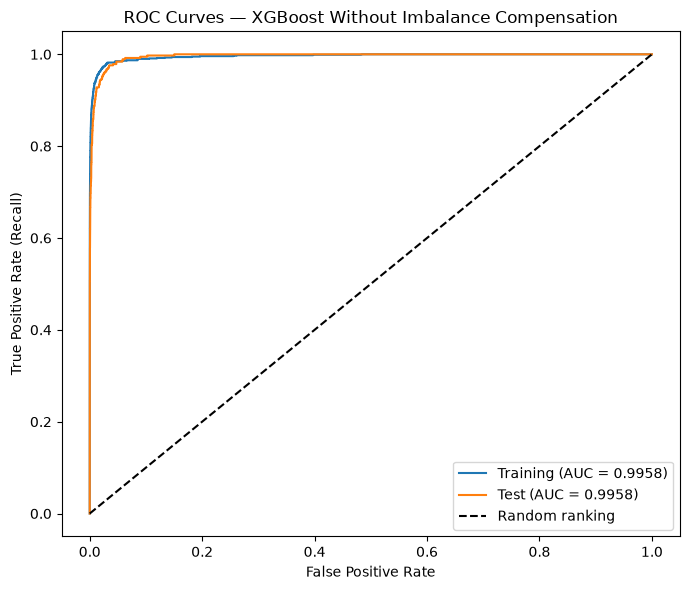

Evaluation summary:


,misclassification_rate,pos_recall,specificity,AUC
Training,0.004550,0.787000,0.998983,0.995811
Test,0.008563,0.693333,0.998592,0.995770


Selected alpha: 0.1
Mean CV error: 0.006967
Test error: 0.008563


In [24]:
# GridSearchCV has already refitted this pipeline on all training data
xgb_best = xgb_search.best_estimator_

xgb_results = {}
plt.figure(figsize=(7, 6))

# Test data uses its own median imputation, following the assignment footnote
for name, X, y_true in [
    ("Training", X_train, y_train_binary),
    ("Test", X_test_imputed, y_test_binary)
]:
    y_pred = xgb_best.predict(X)
    pos_index = list(xgb_best.classes_).index(1)
    scores = xgb_best.predict_proba(X)[:, pos_index]

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    error = 1 - accuracy_score(y_true, y_pred)
    auc = roc_auc_score(y_true, scores)
    fpr, tpr, _ = roc_curve(y_true, scores)

    xgb_results[name] = {
        "misclassification_rate": error,
        "pos_recall": tp / (tp + fn),
        "specificity": tn / (tn + fp),
        "AUC": auc
    }

    print(f"\n{name} confusion matrix:")
    display(pd.DataFrame(
        cm,
        index=["Actual neg", "Actual pos"],
        columns=["Predicted neg", "Predicted pos"]
    ))

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], "k--", label="Random ranking")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves — XGBoost Without Imbalance Compensation")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Evaluation summary:")
display(pd.DataFrame(xgb_results).T)

print(f"Selected alpha: {xgb_search.best_params_['model__reg_alpha']}")
print(f"Mean CV error: {1 - xgb_search.best_score_:.6f}")
print(f"Test error: {xgb_results['Test']['misclassification_rate']:.6f}")

Five-fold stratified CV selected $\alpha=0.1$ from {0.01, 0.1, 1, 10}. Mean CV error was 0.6967%, compared with test error of 0.8563%. Test AUC was 0.9958, but positive-class recall was only 69.33% (115 missed failures), illustrating that strong ranking does not guarantee high recall at the default threshold.

**Implementation limitation:** This uses `gbtree` with L1 regularization, not logistic regression at each node; the assignment's model-tree requirement remains unconfirmed.

### (f) Use SMOTE to pre-process your data

In [27]:
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Apply preprocessing and SMOTE within each training fold
smote_pipeline = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("smote", SMOTE(
        sampling_strategy="auto",
        k_neighbors=5,
        random_state=42
    )),
    ("model", clone(xgb_pipeline.named_steps["model"]))
])

# Use the same alpha candidates and CV splits as in part (e)
smote_search = GridSearchCV(
    estimator=smote_pipeline,
    param_grid=alpha_grid,
    scoring="accuracy",
    cv=cv_strategy,
    refit=True,
    n_jobs=1,
    verbose=1,
    error_score="raise"
)

# Start with the original training data, before imputation or resampling
smote_search.fit(X_train, y_train_binary)

smote_cv_results = pd.DataFrame({
    "alpha": [
        params["model__reg_alpha"]
        for params in smote_search.cv_results_["params"]
    ],
    "mean_cv_error": 1 - smote_search.cv_results_["mean_test_score"],
    "std_cv_error": smote_search.cv_results_["std_test_score"]
}).sort_values("mean_cv_error")

display(smote_cv_results)

print("Best alpha:", smote_search.best_params_["model__reg_alpha"])
print(f"Best mean CV error: {1 - smote_search.best_score_:.6f}")

Fitting 5 folds for each of 4 candidates, totalling 20 fits


,alpha,mean_cv_error,std_cv_error
2,1.00,0.022983,0.001084
0,0.01,0.023067,0.001384
1,0.10,0.023183,0.001226
3,10.00,0.023700,0.001399


Best alpha: 1.0
Best mean CV error: 0.022983



Training confusion matrix:


,Predicted neg,Predicted pos
Actual neg,57686,1314
Actual pos,59,941



Test confusion matrix:


,Predicted neg,Predicted pos
Actual neg,15268,357
Actual pos,26,349


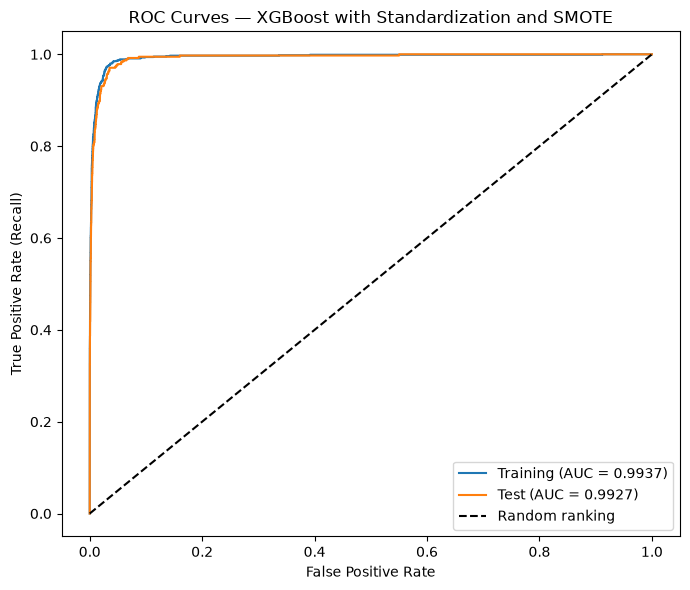

Evaluation summary:


,misclassification_rate,pos_recall,specificity,AUC
Training,0.022883,0.941000,0.977729,0.993725
Test,0.023937,0.930667,0.977152,0.992686


Selected alpha: 1.0
Mean CV error: 0.022983
Test error: 0.023937

Test performance comparison:


,misclassification_rate,pos_recall,specificity,AUC
Without SMOTE,0.008563,0.693333,0.998592,0.995770
With standardization and SMOTE,0.023937,0.930667,0.977152,0.992686


In [28]:
# Use the best pipeline refitted on the full training set
smote_best = smote_search.best_estimator_

smote_results = {}
plt.figure(figsize=(7, 6))

# Evaluate original observations, without resampling
for name, X, y_true in [
    ("Training", X_train, y_train_binary),
    ("Test", X_test_imputed, y_test_binary)
]:
    y_pred = smote_best.predict(X)
    pos_index = list(smote_best.classes_).index(1)
    scores = smote_best.predict_proba(X)[:, pos_index]

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    error = 1 - accuracy_score(y_true, y_pred)
    auc = roc_auc_score(y_true, scores)
    fpr, tpr, _ = roc_curve(y_true, scores)

    smote_results[name] = {
        "misclassification_rate": error,
        "pos_recall": tp / (tp + fn),
        "specificity": tn / (tn + fp),
        "AUC": auc
    }

    print(f"\n{name} confusion matrix:")
    display(pd.DataFrame(
        cm,
        index=["Actual neg", "Actual pos"],
        columns=["Predicted neg", "Predicted pos"]
    ))

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], "k--", label="Random ranking")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves — XGBoost with Standardization and SMOTE")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Evaluation summary:")
display(pd.DataFrame(smote_results).T)

print(f"Selected alpha: {smote_search.best_params_['model__reg_alpha']}")
print(f"Mean CV error: {1 - smote_search.best_score_:.6f}")
print(f"Test error: {smote_results['Test']['misclassification_rate']:.6f}")

# Compare test performance with part (e)
comparison = pd.DataFrame({
    "Without SMOTE": xgb_results["Test"],
    "With standardization and SMOTE": smote_results["Test"]
}).T

print("\nTest performance comparison:")
display(comparison)

## 2. ISLR 6.6.3

| Part | Choice | Justification as $s$ increases |
|---|---|---|
| (a) | iv | Training RSS cannot increase as the feasible set expands; it eventually levels off. |
| (b) | ii | Test RSS typically decreases as underfitting declines, then increases due to overfitting. |
| (c) | iii | Greater flexibility generally increases sensitivity to the training sample and hence variance. |
| (d) | iv | Relaxing the constraint generally reduces squared bias. |
| (e) | v | Irreducible error is inherent noise and does not depend on $s$. |

The patterns in (b)-(d) are general expectations, not guarantees for every dataset.

## 3. ISLR 6.6.5

Let (x_1=x_{11}=x_{12}) and (x_2=x_{21}=x_{22}). Since the variables are centered, the intercept is zero.

(a) Ridge regression optimization problem

The ridge estimates minimize

[
(y_1-x_1(\beta_1+\beta_2))^2
+(y_2-x_2(\beta_1+\beta_2))^2
+\lambda(\beta_1^2+\beta_2^2).
]

The first two terms represent the training RSS, and the last term is the L2 penalty.

(b) Why the ridge coefficients are equal

The RSS depends only on the sum (t=\beta_1+\beta_2). For any fixed sum,

[
\beta_1^2+\beta_2^2
=\frac{t^2}{2}+\frac{(\beta_1-\beta_2)^2}{2}.
]

The penalty is minimized when (\beta_1-\beta_2=0). Therefore, replacing unequal coefficients with equal coefficients preserves the predictions while reducing the penalty. Hence, for (\lambda>0),

[
\hat{\beta}_1=\hat{\beta}_2.
]

(c) Lasso optimization problem

The lasso estimates minimize

[
(y_1-x_1(\beta_1+\beta_2))^2
+(y_2-x_2(\beta_1+\beta_2))^2
+\lambda(|\beta_1|+|\beta_2|).
]

Unlike ridge regression, lasso penalizes the sum of the absolute coefficient values.

(d) Why the lasso coefficients can be non-unique

Again, the RSS depends only on (t=\beta_1+\beta_2). By the triangle inequality,

[
|\beta_1|+|\beta_2|\geq|\beta_1+\beta_2|=|t|.
]

Equality holds when the coefficients have the same sign, allowing either coefficient to be zero. Thus, for any fixed sum, all such allocations produce identical predictions and the same minimum L1 penalty.

Let (t^*) minimize

[
(y_1-x_1t)^2+(y_2-x_2t)^2+\lambda|t|.
]

If (t^*\neq0), every coefficient pair of the form

[
\hat{\beta}_1=a,t^,\qquad
\hat{\beta}_2=(1-a)t^,
\qquad 0\leq a\leq1
]

is an optimal solution. For example, ((t^,0)), ((0,t^)), and ((t^/2,t^/2)) all achieve the same objective value.

Therefore, lasso can have infinitely many coefficient solutions, even though their fitted predictions are identical. However, if regularization produces (t^*=0), the unique solution for (\lambda>0) is (\hat{\beta}_1=\hat{\beta}_2=0).

## 4. ISLR 8.4.5

Under majority voting, six trees predict Red because their estimated probabilities exceed 0.5, while four trees predict Green. Therefore, the final classification is **Red**.

Under probability averaging, the mean estimated probability of Red is 4.5 / 10 = 0.45. Since this is below 0.5, the final classification is **Green**.

## 5. ISLR 9.7.3

In [2]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([
    [3, 4],  # Observation 1
    [2, 2],  # Observation 2
    [4, 4],  # Observation 3
    [1, 4],  # Observation 4
    [2, 1],  # Observation 5
    [4, 3],  # Observation 6
    [4, 1]   # Observation 7
])

colors = ["red"] * 4 + ["blue"] * 3
line_x = np.linspace(0.5, 4.5, 200)

def plot_observations(title, points=None):
    if points is None:
        points = X

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(points[:, 0], points[:, 1], c=colors, s=80)

    for i, (x1, x2) in enumerate(points, start=1):
        ax.annotate(
            str(i), (x1, x2),
            xytext=(7, 7),
            textcoords="offset points"
        )

    ax.set(
        xlim=(0.5, 4.5),
        ylim=(0.5, 4.5),
        xlabel="X1",
        ylabel="X2",
        title=title
    )
    ax.set_aspect("equal")
    ax.grid(alpha=0.25)

    return ax

**(a)** The shared plot below shows all seven observations, labeled by observation number and colored by class.

**(b)** The optimal separator is $0.5-X_1+X_2=0$, or $X_2=X_1-0.5$, halfway between the closest parallel class boundaries.

**(c)** Predict Red if $0.5-X_1+X_2>0$; otherwise predict Blue. Thus $(\beta_0,\beta_1,\beta_2)=(0.5,-1,1)$.

**(d)** The dashed margin boundaries are $X_2=X_1$ and $X_2=X_1-1$. The one-sided margin is $M=0.5/\sqrt{2}\approx0.3536$; the full margin width is $2M\approx0.7071$.

**(e)** The circled support vectors are observations **2, 3, 5, and 6**, which lie on the margin boundaries. The following shared plot answers (a), (b), (d), and (e).

Support vectors: observations 2, 3, 5, and 6


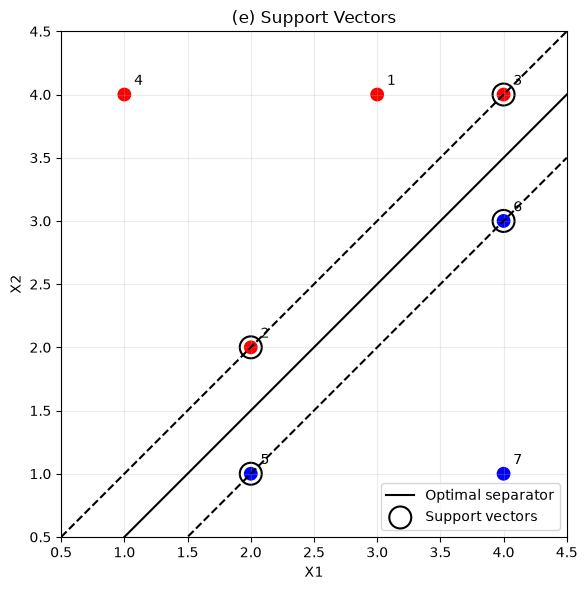

In [7]:
ax = plot_observations("(e) Support Vectors")

ax.plot(line_x, line_x - 0.5, "k-", label="Optimal separator")
ax.plot(line_x, line_x, "k--")
ax.plot(line_x, line_x - 1, "k--")

support_indices = [1, 2, 4, 5]
support_points = X[support_indices]

ax.scatter(
    support_points[:, 0],
    support_points[:, 1],
    s=250,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    label="Support vectors"
)

print("Support vectors: observations 2, 3, 5, and 6")

ax.legend()
plt.tight_layout()
plt.show()

**(f)** Observation 7 is not a support vector and lies beyond the Blue margin boundary. A sufficiently small movement leaves the support vectors and maximal margin hyperplane unchanged.

**(g)** A non-optimal separator is $0.25-X_1+X_2=0$. It separates all observations, but its minimum distance to the data, $0.25/\sqrt{2}$, is smaller than the optimal margin.

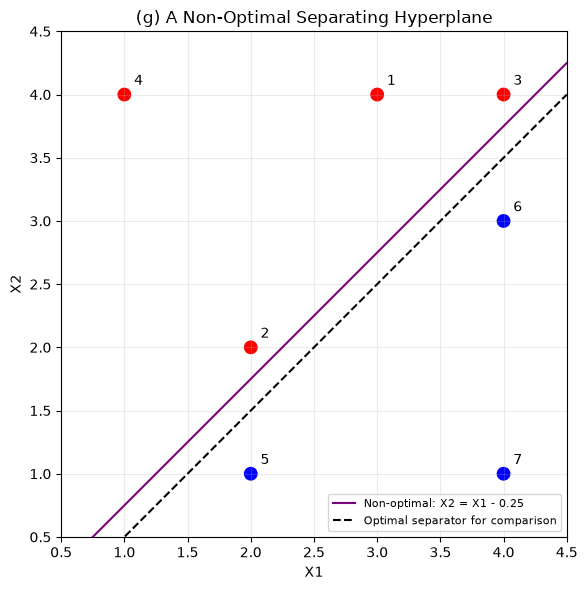

In [9]:
ax = plot_observations("(g) A Non-Optimal Separating Hyperplane")

ax.plot(
    line_x, line_x - 0.25,
    color="purple",
    label="Non-optimal: X2 = X1 - 0.25"
)

ax.plot(
    line_x, line_x - 0.5,
    "k--",
    label="Optimal separator for comparison"
)

ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**(h)** Add a Blue observation at $(2,3)$, inside the Red convex hull. Any linear half-plane containing all Red points must also contain this Blue point, so the classes are no longer linearly separable.

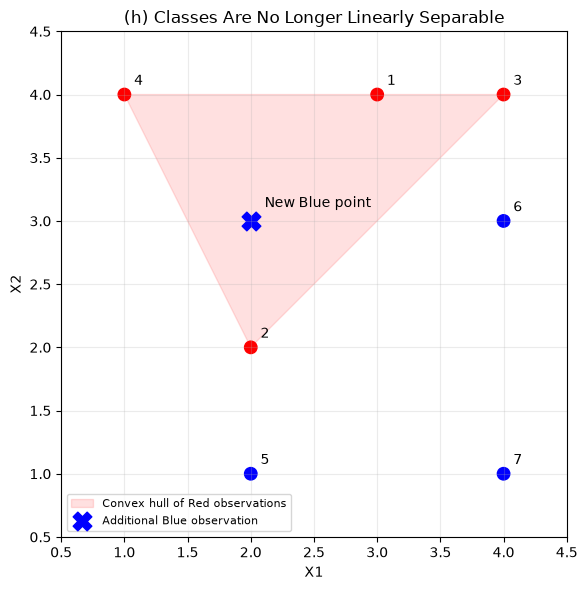

In [10]:
ax = plot_observations("(h) Classes Are No Longer Linearly Separable")

# Shade the convex hull of the Red observations
ax.fill(
    [1, 2, 4],
    [4, 2, 4],
    color="red",
    alpha=0.12,
    label="Convex hull of Red observations"
)

ax.scatter(
    2, 3,
    color="blue",
    marker="X",
    s=180,
    label="Additional Blue observation"
)

ax.annotate(
    "New Blue point",
    (2, 3),
    xytext=(10, 10),
    textcoords="offset points"
)

ax.legend(fontsize=8)
plt.tight_layout()
plt.show()